### Population view with randomised initial conditions

As section 1 of `CPA_population.ipynb` (mean change), but every neuron starts from a random state instead of (v, u, w) = (-60, 0, 0):
v_0 ~ U[-100, 20] mV, u_0 ~ U[-100, 100], w_0 ~ U[-50, 50] (`simulate_runs(random_init = True)`).

Only the example conditions are simulated (spike times only).

In [1]:
import inspect
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

from CPA_with_AQUA import *
from aqua.plotting_functions import plot_raster

In [2]:
N_REPEATS = 250
T = 10000           # ms, as in simulate_w_cusum
DT = 0.1
CHANGEPOINT = T // 2
T_DISCARD = 200     # ms, initial transient (as in simulate_w_cusum)
BIN = 50            # ms, PSTH bin width for the full trial
BIN_ZOOM = 10       # ms, PSTH bin width for the zoom around the change point
ZOOM = 500          # ms either side of the change point
EXAMPLE_F = [0, 240, 270, 300, 350]      # columns
EXAMPLES_MEAN = [(25.0, 10), (50, 10)]   # (variance, step height)
SEED = 0

sim = {k: p.default for k, p in inspect.signature(simulate_runs).parameters.items()
       if p.default is not inspect.Parameter.empty}

## Simulate
Same layout as the saved spike files: `saved['spikes'][(rep, v, h, f)]`.

In [3]:
def simulate_examples(T, changepoint, seed = SEED, **kw):
    '''spike times of the EXAMPLES_MEAN conditions x EXAMPLE_F, in the saved spike file layout.
    kw go to simulate_runs (e.g. random_init, t_warmup, var_warmup)'''
    np.random.seed(seed)
    f_values = np.array(EXAMPLE_F)
    var = np.array(sorted({v for v, _ in EXAMPLES_MEAN}))
    d_H = np.array(sorted({h for _, h in EXAMPLES_MEAN}))

    spikes = {}
    for reps, spike_arr in simulate_runs(RS, f_values, d_H, var, N_REPEATS, T, changepoint, dt = DT,
                                         repeats_per_batch = 25, save_all = False, **kw):
        row = 0
        for rep in reps:
            for v in var:
                for h in d_H:
                    for f in f_values:
                        s = spike_arr[row] if spike_arr.shape[1] > 0 else np.array([])
                        spikes[(rep, v, h, f)] = s[~np.isnan(s)]
                        row += 1
    return {'spikes': spikes, 'N_repeats': N_REPEATS, 'T': T, 'changepoint': changepoint, **kw}


saved_rand = simulate_examples(T, CHANGEPOINT, random_init = True)

Repeats 0-24 of 250


  0%|          | 0/99999 [00:00<?, ?it/s]

100%|██████████| 99999/99999 [00:21<00:00, 4740.51it/s]


Repeats 25-49 of 250


100%|██████████| 99999/99999 [00:20<00:00, 4811.91it/s]


Repeats 50-74 of 250


... (11 outputs left out)

Repeats 200-224 of 250


100%|██████████| 99999/99999 [00:19<00:00, 5081.70it/s]


Repeats 225-249 of 250


100%|██████████| 99999/99999 [00:19<00:00, 5006.21it/s]


In [4]:
def spike_matrix(saved, v, h, f):
    '''NaN-padded (repeats x spikes) array of spike times [ms] for one condition, for plot_raster'''
    rows = [np.asarray(saved['spikes'][(rep, v, h, f)], dtype = float) for rep in range(saved['N_repeats'])]
    rows = [r[~np.isnan(r)] for r in rows]
    S = np.full((len(rows), max(len(r) for r in rows)), np.nan)
    for i, r in enumerate(rows):
        S[i, :len(r)] = r
    return S


def psth(S, T, bin_ms):
    '''trial-averaged firing rate [Hz]: bin centres [ms] and rate'''
    edges = np.arange(0, T + bin_ms, bin_ms)
    counts, _ = np.histogram(S[~np.isnan(S)], bins = edges)
    return 0.5*(edges[:-1] + edges[1:]), counts / (S.shape[0] * bin_ms/1000)


def mean_rate(S, t0, t1):
    '''mean rate [Hz] over all trials in [t0, t1)'''
    s = S[~np.isnan(S)]
    return np.sum((s >= t0) & (s < t1)) / (S.shape[0] * (t1 - t0)/1000)


def raster_psth_grid(saved, v, h, example_f, title_fn, bin_ms, xlim = None):
    '''
    One column per autapse strength: raster of all repeats (top) and PSTH (bottom).
    title_fn(f, v, h) gives each column's title. xlim = (t0, t1) zooms in.
    If saved has a t_warmup > 0, that high-noise period is shaded orange and excluded from the pre rate.
    '''
    T, cp = saved['T'], saved['changepoint']
    t_warm = saved.get('t_warmup', 0)
    fig, ax = plt.subplots(2, len(example_f), figsize = (4*len(example_f), 6), sharex = 'col', sharey = 'row',
                           gridspec_kw = {'height_ratios': [3, 1]}, squeeze = False)
    for c, f in enumerate(example_f):
        S = spike_matrix(saved, v, h, f)
        fig, ax[0, c] = plot_raster(S, T, ax = ax[0, c], linewidth = 0.4)
        ax[0, c].set_xlabel('')
        ax[0, c].set_ylabel('Trial' if c == 0 else '')
        ax[0, c].grid(False)
        ax[0, c].set_title(title_fn(f, v, h), fontsize = 10)

        t, rate = psth(S, T, bin_ms)
        ax[1, c].step(t, rate, where = 'mid', color = 'k', lw = 1)
        pre, post = mean_rate(S, max(T_DISCARD, t_warm), cp), mean_rate(S, cp, T)
        ax[1, c].axhline(pre, xmax = 1, color = plt.cm.viridis(0.15), ls = '--', lw = 1.2)
        ax[1, c].axhline(post, color = plt.cm.viridis(0.85), ls = '--', lw = 1.2)
        ax[1, c].text(0.03, 0.95, f'pre {pre:.1f} Hz\npost {post:.1f} Hz', transform = ax[1, c].transAxes,
                      ha = 'left', va = 'top', fontsize = 8, bbox = dict(facecolor = 'white', alpha = 0.8, edgecolor = 'none'))
        ax[1, c].set_xlabel('Time [ms]')
        ax[1, c].set_ylabel(f'Rate [Hz]\n({bin_ms} ms bins)' if c == 0 else '')

        for a in ax[:, c]:
            a.axvline(cp, color = 'r', ls = '--', lw = 1)
            a.axvspan(0, T_DISCARD, color = 'grey', alpha = 0.3, lw = 0)
            if t_warm > 0:
                a.axvspan(0, t_warm, color = 'orange', alpha = 0.2, lw = 0)
            a.set_xlim(*(xlim if xlim is not None else (0, T)))
    fig.tight_layout()
    return fig, ax

In [5]:
def title_mean(f, v, h):
    return f'f = {f} pA, e = {sim["e"]}, τ = {sim["tau"]} ms\nstep h = {h} pA, var = {v} pA²'

## Mean change, random initial conditions

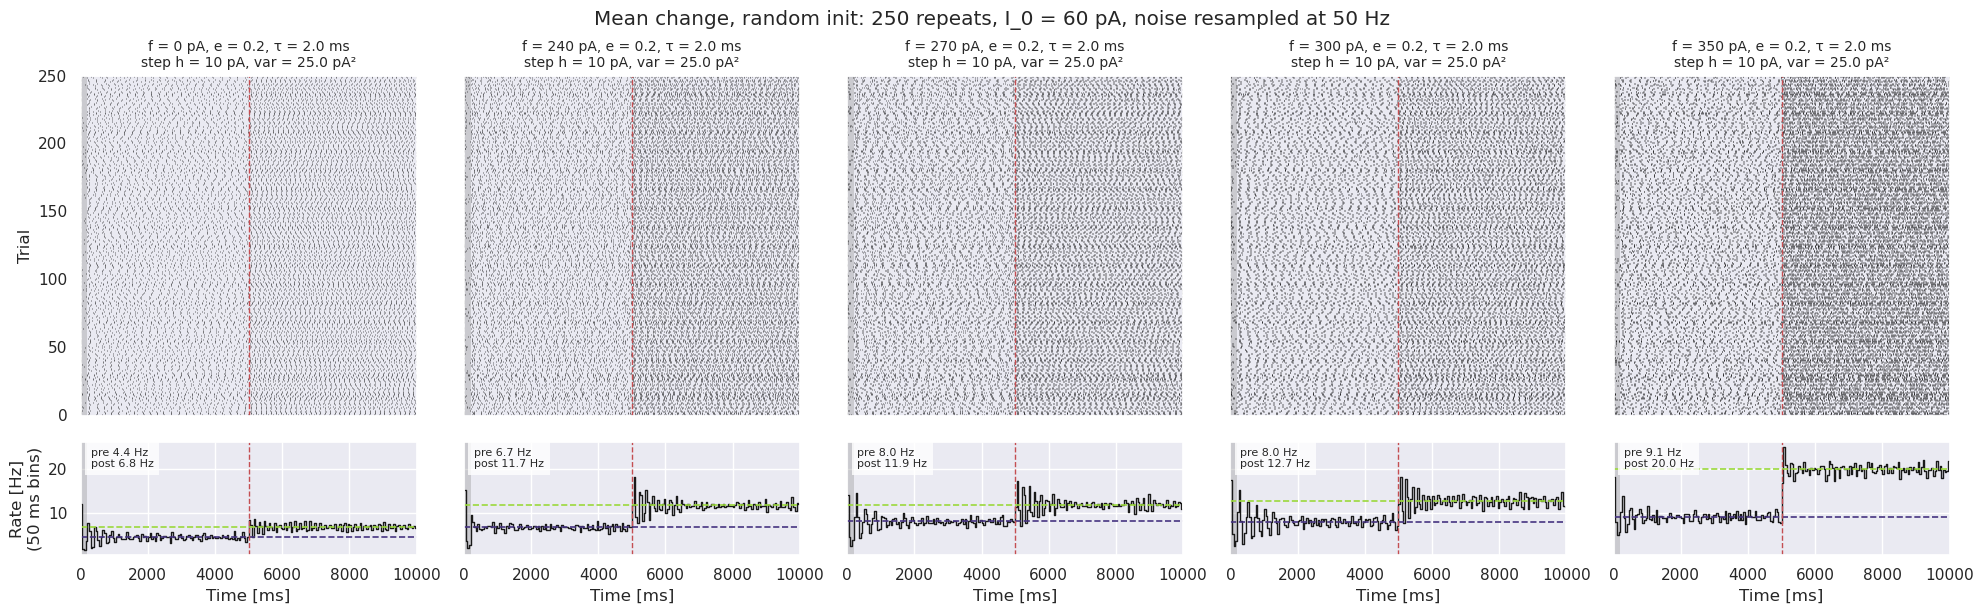

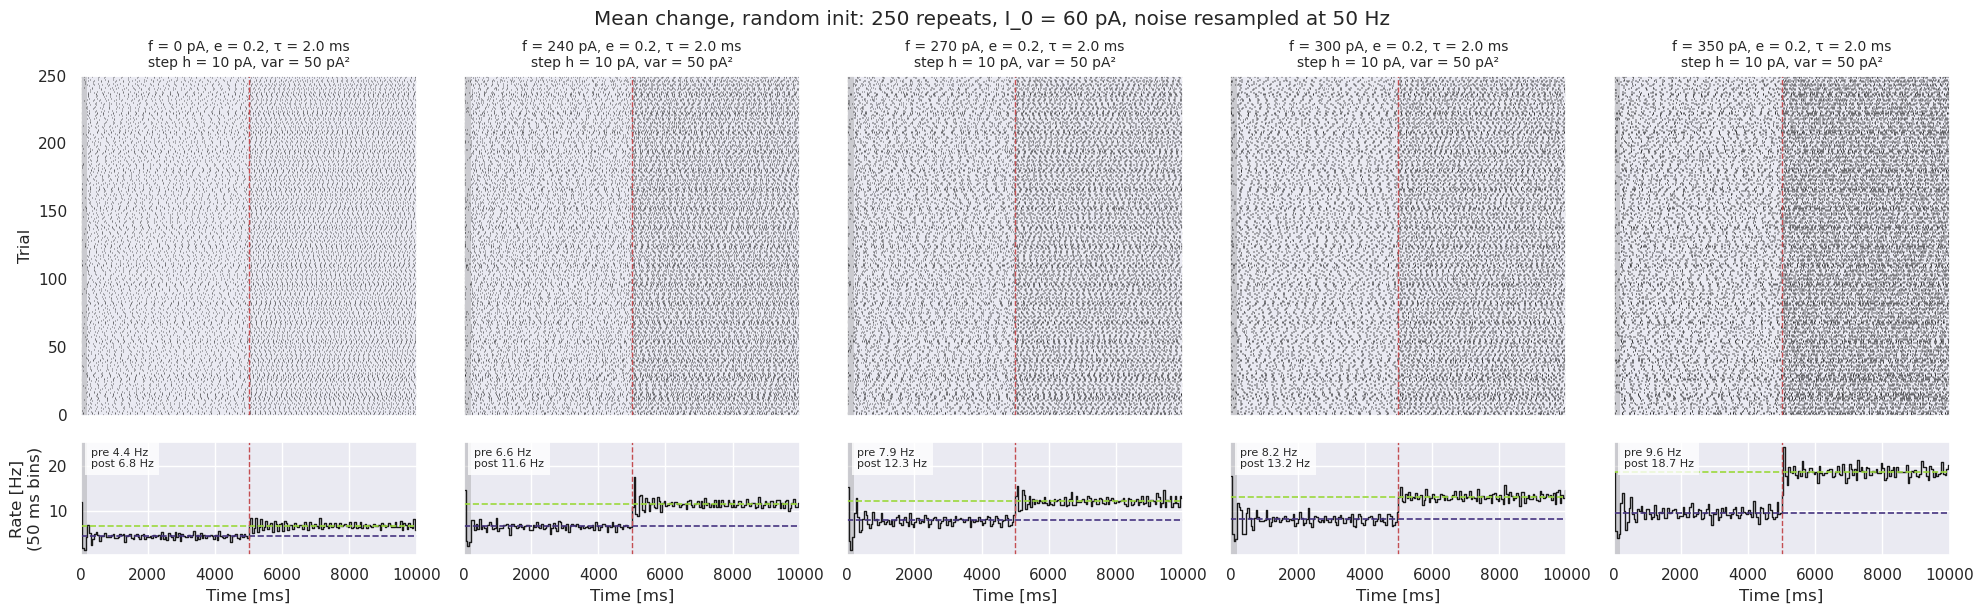

In [6]:
for v, h in EXAMPLES_MEAN:
    fig, ax = raster_psth_grid(saved_rand, v, h, EXAMPLE_F, title_mean, BIN)
    fig.suptitle(f'Mean change, random init: {N_REPEATS} repeats, I_0 = {sim["I_0"]} pA, noise resampled at {sim["noise_rate"]} Hz', y = 1.02)
    plt.show()

#### Zoom around the change point

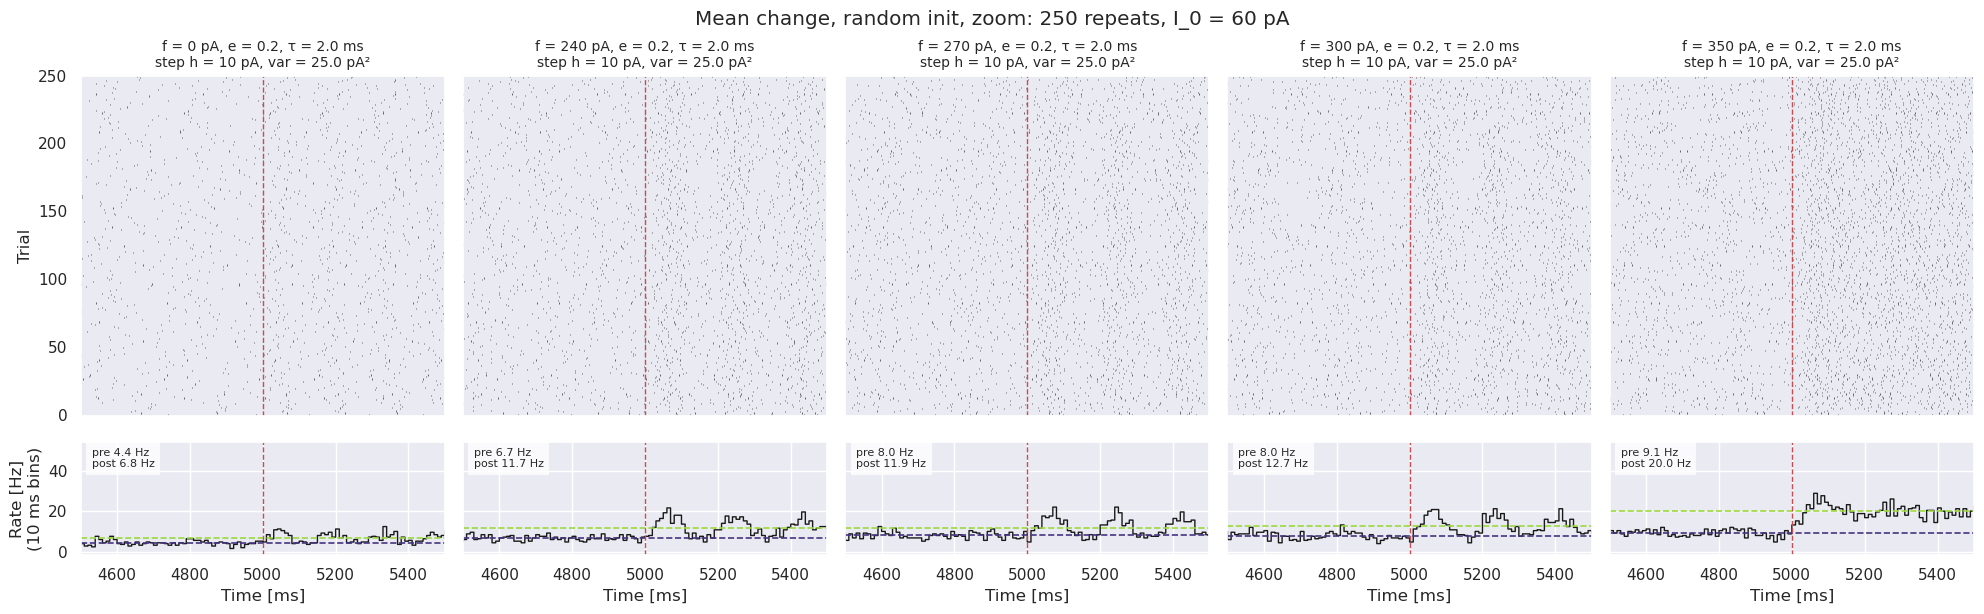

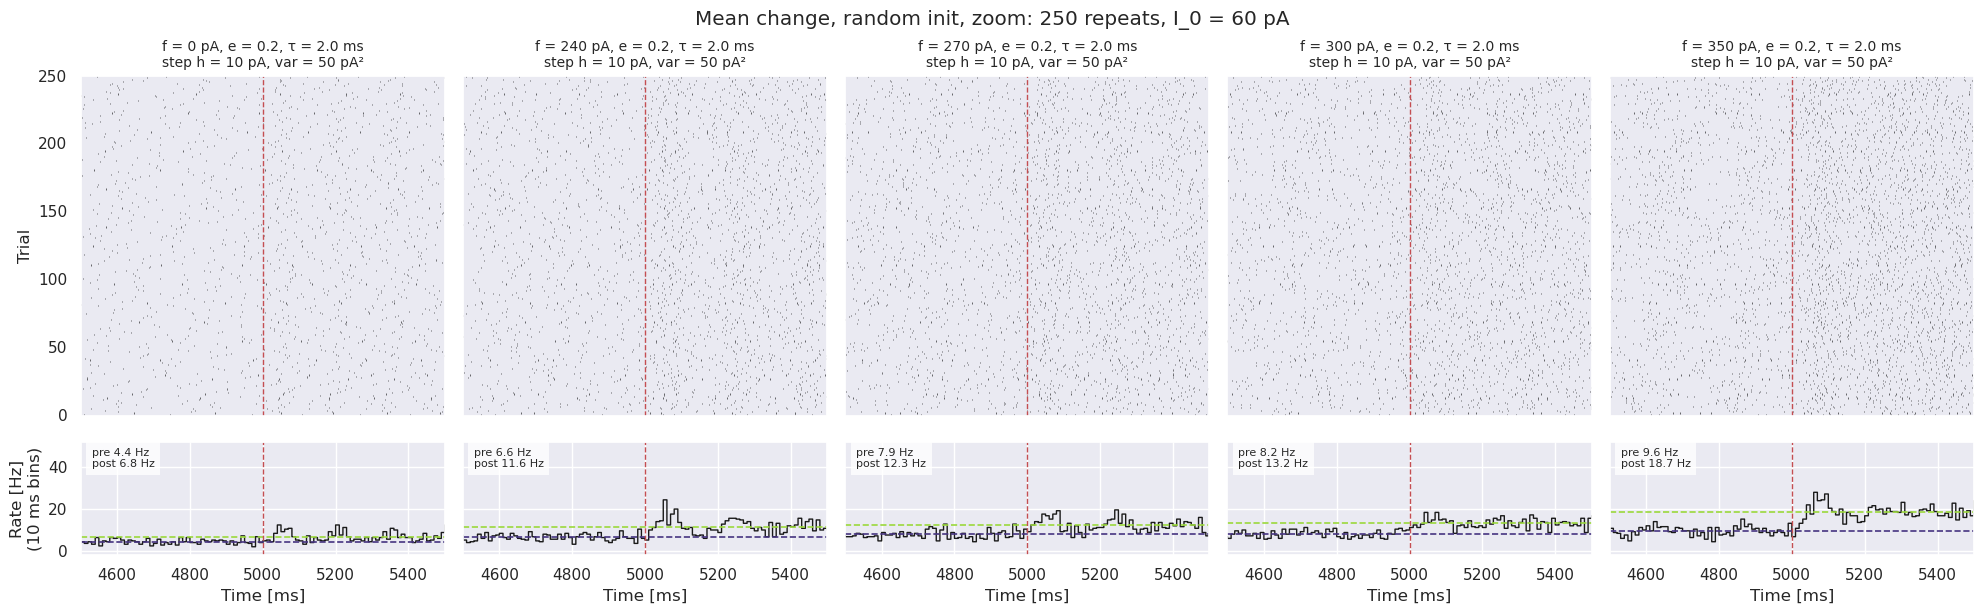

In [7]:
for v, h in EXAMPLES_MEAN:
    fig, ax = raster_psth_grid(saved_rand, v, h, EXAMPLE_F, title_mean, BIN_ZOOM, xlim = (CHANGEPOINT - ZOOM, CHANGEPOINT + ZOOM))
    fig.suptitle(f'Mean change, random init, zoom: {N_REPEATS} repeats, I_0 = {sim["I_0"]} pA', y = 1.02)
    plt.show()

## Random initial conditions + high-noise warm-up
Each neuron again starts from a random state, and for the first `T_WARM` ms the noise variance is raised to `VAR_WARM` (mean input unchanged), to scatter the trials further before they settle. After that the noise drops back to the condition's variance. The run is extended by `T_WARM` so there are still 5 s before and after the change point.

The orange band marks the high-noise warm-up; the pre-change rate is measured from its end.

In [8]:
T_WARM = 500       # ms
VAR_WARM = 250      # pA^2
T_W = T + T_WARM
CP_W = CHANGEPOINT + T_WARM

saved_warm = simulate_examples(T_W, CP_W, random_init = True, t_warmup = T_WARM, var_warmup = VAR_WARM)

Repeats 0-24 of 250


100%|██████████| 104999/104999 [00:20<00:00, 5031.21it/s]


Repeats 25-49 of 250


100%|██████████| 104999/104999 [00:20<00:00, 5078.87it/s]


Repeats 50-74 of 250


100%|██████████| 104999/104999 [00:20<00:00, 5084.51it/s]


... (10 outputs left out)

Repeats 200-224 of 250


100%|██████████| 104999/104999 [00:21<00:00, 4882.58it/s]


Repeats 225-249 of 250


100%|██████████| 104999/104999 [00:21<00:00, 4952.49it/s]


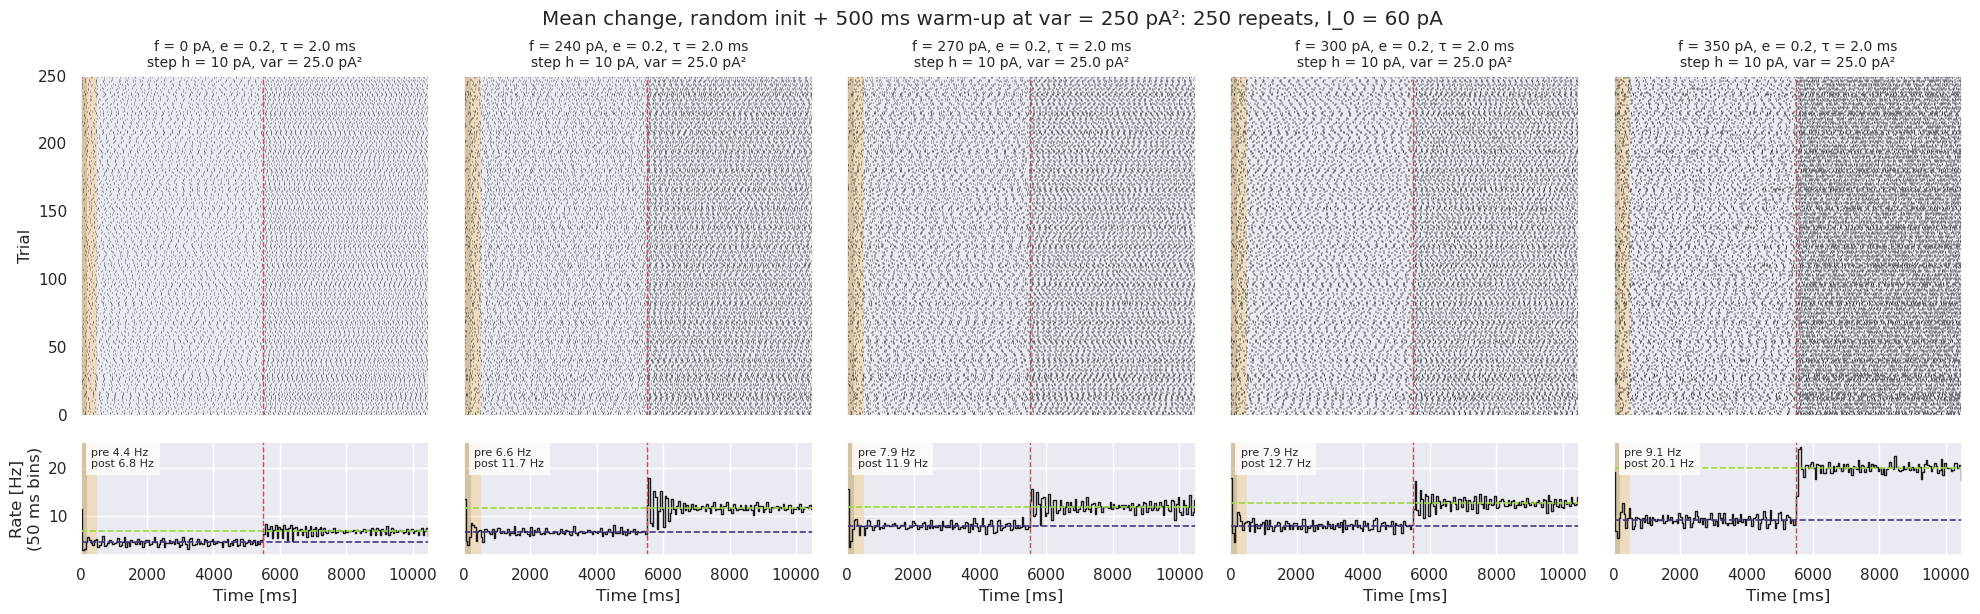

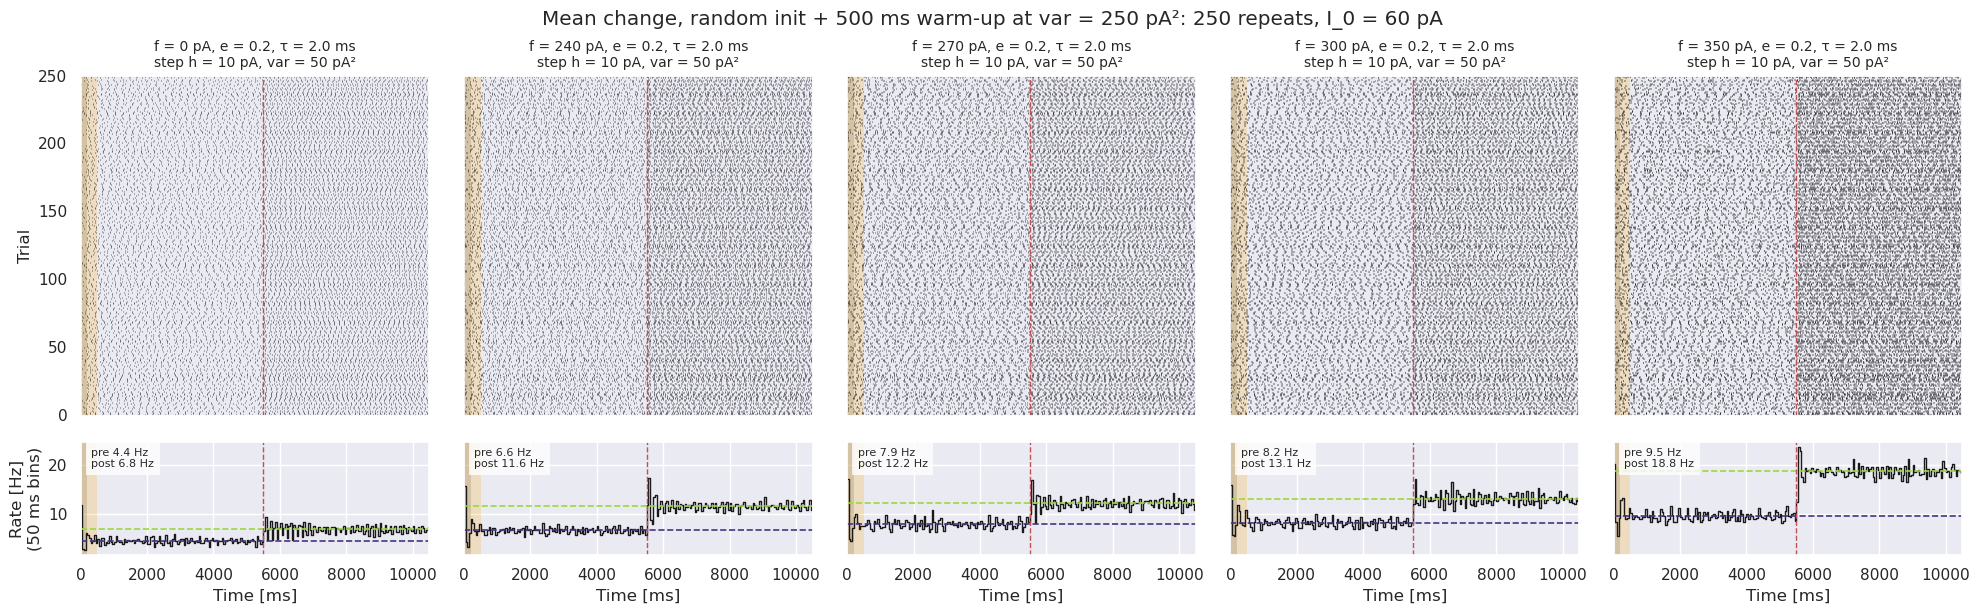

In [9]:
for v, h in EXAMPLES_MEAN:
    fig, ax = raster_psth_grid(saved_warm, v, h, EXAMPLE_F, title_mean, BIN)
    fig.suptitle(f'Mean change, random init + {T_WARM} ms warm-up at var = {VAR_WARM} pA²: {N_REPEATS} repeats, I_0 = {sim["I_0"]} pA', y = 1.02)
    plt.show()

#### Zoom around the change point

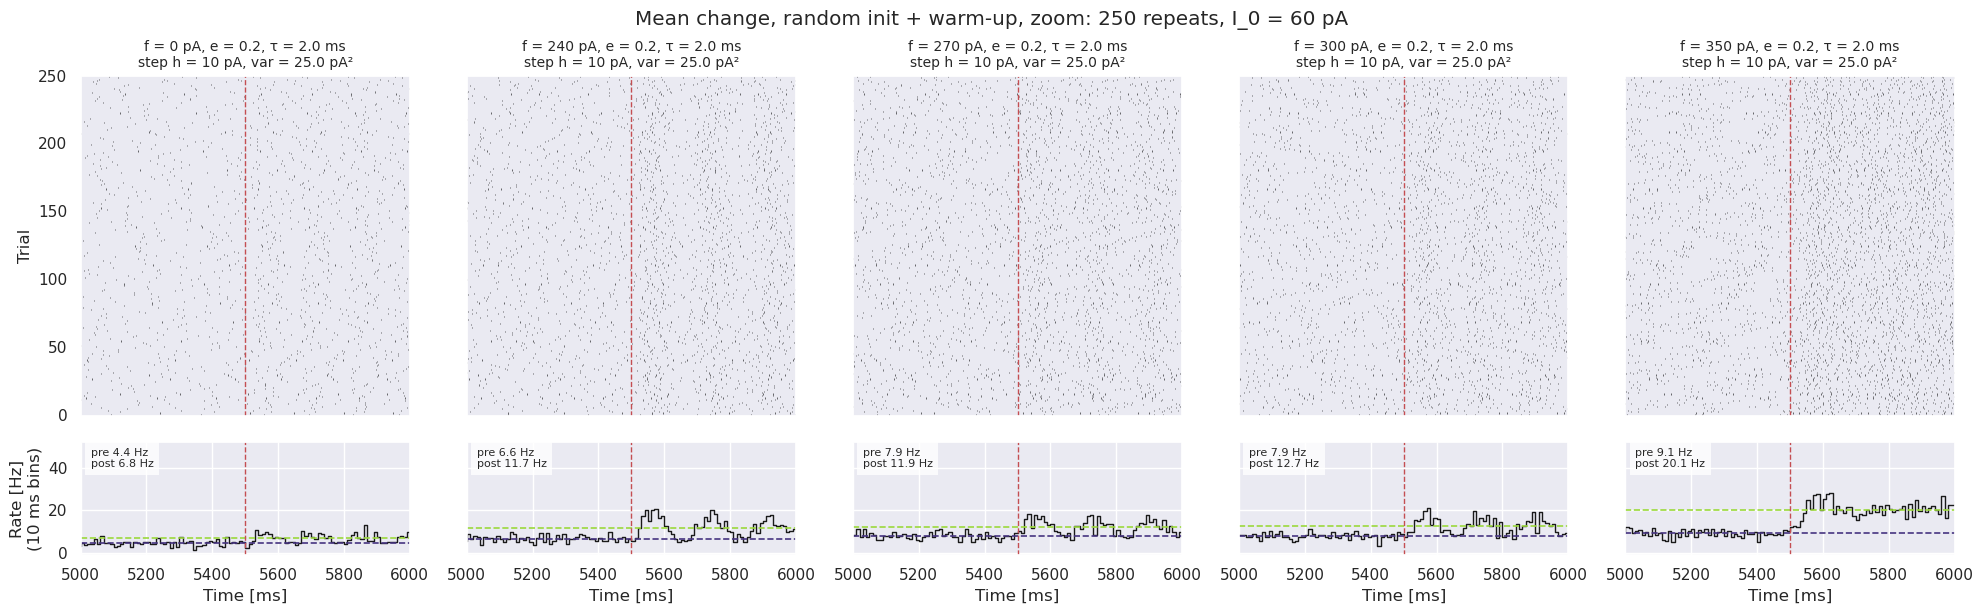

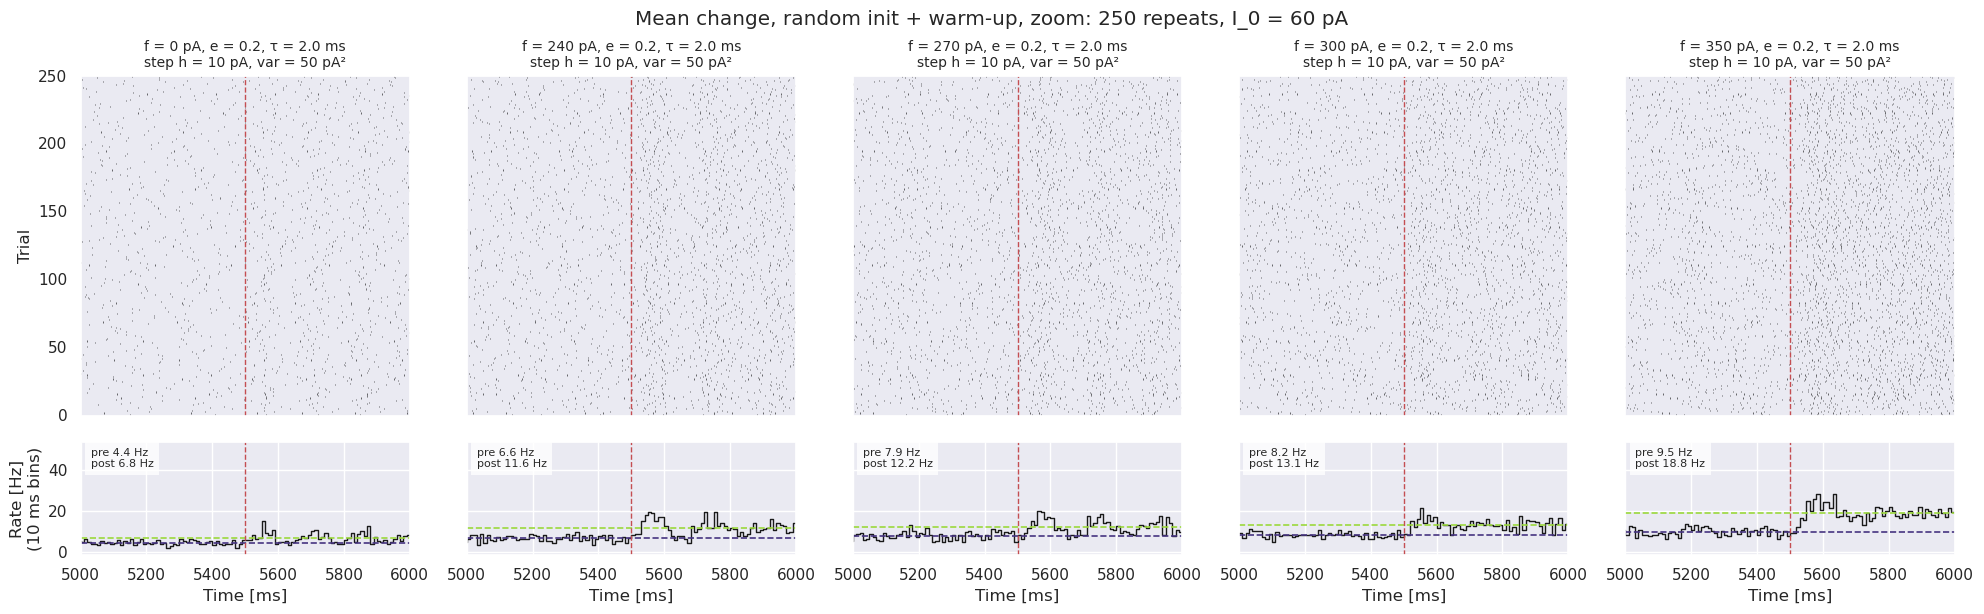

In [10]:
for v, h in EXAMPLES_MEAN:
    fig, ax = raster_psth_grid(saved_warm, v, h, EXAMPLE_F, title_mean, BIN_ZOOM, xlim = (CP_W - ZOOM, CP_W + ZOOM))
    fig.suptitle(f'Mean change, random init + warm-up, zoom: {N_REPEATS} repeats, I_0 = {sim["I_0"]} pA', y = 1.02)
    plt.show()